<a href="https://colab.research.google.com/github/yashrajsharan18/Machine-Learning/blob/main/Sequential_Gene_Sequence_Analysis_Using_Hidden_Markov_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!wget -c https://ftp.ebi.ac.uk/pub/databases/Pfam/current_release/Pfam-A.seed.gz
!ls -lh Pfam-A.seed.gz


--2026-11-17 03:11:47--  https://ftp.ebi.ac.uk/pub/databases/Pfam/current_release/Pfam-A.seed.gz
Resolving ftp.ebi.ac.uk (ftp.ebi.ac.uk)... 193.62.193.165
Connecting to ftp.ebi.ac.uk (ftp.ebi.ac.uk)|193.62.193.165|:443... connected.
HTTP request sent, awaiting response... 416 Requested Range Not Satisfiable

    The file is already fully retrieved; nothing to do.

-rw-r--r-- 1 root root 224M Sep 18 10:30 Pfam-A.seed.gz


In [ ]:
!gunzip -k Pfam-A.seed.gz

# Check extracted dataset
!ls -lh Pfam-A.seed

gzip: Pfam-A.seed already exists; do you wish to overwrite (y or n)? n
	not overwritten
-rw-r--r-- 1 root root 703M Sep 18 10:30 Pfam-A.seed


In [ ]:
!pip install biopython -q

import numpy as np
import matplotlib.pyplot as plt
from Bio import AlignIO
import gzip

In [ ]:
alignments = AlignIO.parse("Pfam-A.seed", "stockholm")

alignment = next(alignments)

sequences = [str(record.seq) for record in alignment]

print("Number of sequences:", len(sequences))
print("First protein sequence:")
print(sequences[0])

Number of sequences: 5
First protein sequence:
SQTSWIVSRMLEY-PRGGFFYSTDMACMMEG-LAEELAGGHKDEVLIVSGRNGDDEVFKE--FPNVRAADGLKGPNS-IDPETKLVLII--DV---SPTAISNALAAT--LQEFLIPVWVFCNHTRTL-----TASVTRRLGYKLWP-KGTYTPYICEK


Protein Sequence: SQTSWIVSRMLEYPRGGFFYSTDMACMMEGLAEELAGGHKDEVLIVSGRNGDDEVFKEFPNVRAADGLKGPNSIDPETKLVLIIDVSPTAISNALAATLQ
Sequence Length: 141

Initial Probabilities:
 [0.33333333 0.33333333 0.33333333]

Transition Matrix:
 [[0.8  0.15 0.05]
 [0.1  0.8  0.1 ]
 [0.05 0.15 0.8 ]]

Emission Matrix:
 [[0.13306452 0.00806452 0.01612903 0.02217742 0.08467742 0.02419355
  0.00604839 0.10887097 0.01612903 0.16935484 0.06048387 0.01209677
  0.01814516 0.00604839 0.01612903 0.02016129 0.02419355 0.13306452
  0.0483871  0.07258065]
 [0.02777778 0.06060606 0.02020202 0.02777778 0.01767677 0.18181818
  0.00757576 0.02272727 0.02020202 0.03535354 0.01262626 0.09090909
  0.02272727 0.04545455 0.02020202 0.15151515 0.18181818 0.02777778
  0.01010101 0.01515152]
 [0.03133903 0.01139601 0.13675214 0.18803419 0.01994302 0.03418803
  0.05128205 0.02564103 0.13675214 0.03988604 0.01424501 0.01709402
  0.02564103 0.00854701 0.13675214 0.02849003 0.03418803 0.03133903
  0.01139601 0.01709402]]

Total Observatio

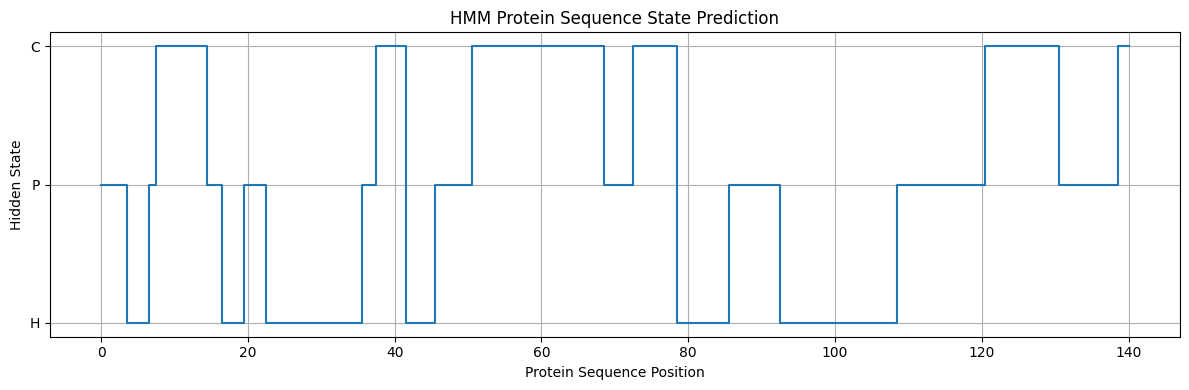


========== FINAL RESULTS ==========
Sequence Length: 141
Forward Log Probability: -418.33874362168035
Forward-Backward Check: 0.9999999999999992
HMM Analysis Completed Successfully!


In [ ]:

# 1. EXTRACT PROTEIN SEQUENCE

sequence = str(alignment[0].seq).upper()
sequence = sequence.replace("-", "").replace(".", "")

amino_acids = list("ACDEFGHIKLMNPQRSTVWY")
sequence = "".join(a for a in sequence if a in amino_acids)

print("Protein Sequence:", sequence[:100])
print("Sequence Length:", len(sequence))

# 2. DEFINE HIDDEN MARKOV MODEL

states = ["H", "P", "C"]

# H = Hydrophobic, P = Polar, C = Charged

N = len(states)
M = len(amino_acids)

initial = np.array([1/3, 1/3, 1/3])

transition = np.array([
    [0.80, 0.15, 0.05],
    [0.10, 0.80, 0.10],
    [0.05, 0.15, 0.80]
])

hydrophobic = list("AVILMFWY")
polar = list("STNQCG")
charged = list("DEKRH")

groups = [hydrophobic, polar, charged]

counts = np.array([sequence.count(a) for a in amino_acids], dtype=float)
background = (counts + 1) / (counts.sum() + M)

emission = np.zeros((N, M))

for i, group in enumerate(groups):
    weights = np.array([
        3.0 if a in group else 0.5
        for a in amino_acids
    ])

    emission[i] = background * weights
    emission[i] /= emission[i].sum()

print("\nInitial Probabilities:\n", initial)
print("\nTransition Matrix:\n", transition)
print("\nEmission Matrix:\n", emission)

# 3. CONVERT SEQUENCE INTO OBSERVATIONS

obs = np.array([amino_acids.index(a) for a in sequence])
n = len(obs)

print("\nTotal Observations:", n)

# 4. FORWARD ALGORITHM WITH SCALING

alpha = np.zeros((n, N))
scales = np.zeros(n)

alpha[0] = initial * emission[:, obs[0]]
scales[0] = alpha[0].sum()
alpha[0] /= scales[0]

for t in range(1, n):
    alpha[t] = (alpha[t-1] @ transition) * emission[:, obs[t]]
    scales[t] = alpha[t].sum()
    alpha[t] /= scales[t]

forward_probability = np.sum(np.log(scales))

print("\nForward Log Probability:", forward_probability)
print("Scaling Factors:", scales[:10])

# 5. BACKWARD ALGORITHM WITH SCALING

beta = np.zeros((n, N))
beta[-1] = 1

for t in range(n-2, -1, -1):
    beta[t] = (
        transition @ (emission[:, obs[t+1]] * beta[t+1])
    ) / scales[t+1]

check = np.sum(
    initial * emission[:, obs[0]] * beta[0]
) / scales[0]

print("\nBackward Algorithm Completed")
print("Forward-Backward Check:", check)

# 6. VITERBI ALGORITHM

log_transition = np.log(transition)
log_emission = np.log(emission)
log_initial = np.log(initial)

viterbi = np.zeros((n, N))
path = np.zeros((n, N), dtype=int)

viterbi[0] = log_initial + log_emission[:, obs[0]]

for t in range(1, n):
    for j in range(N):
        probabilities = viterbi[t-1] + log_transition[:, j]
        path[t, j] = np.argmax(probabilities)

        viterbi[t, j] = (
            np.max(probabilities) + log_emission[j, obs[t]]
        )

# 7. BACKTRACKING AND STATE PREDICTION


best_path = [np.argmax(viterbi[-1])]

for t in range(n-1, 0, -1):
    best_path.append(path[t, best_path[-1]])

best_path.reverse()

predicted_states = [states[i] for i in best_path]

print("\nPredicted Hidden States:")
print(predicted_states[:100])

print("\nState Distribution:")

for state in states:
    print(state, ":", predicted_states.count(state))


# 8. VISUALIZATION


plt.figure(figsize=(12, 4))

plt.step(range(n), best_path, where="mid")

plt.yticks(range(N), states)
plt.xlabel("Protein Sequence Position")
plt.ylabel("Hidden State")
plt.title("HMM Protein Sequence State Prediction")

plt.grid()
plt.tight_layout()
plt.show()
# 9. FINAL RESULTS

print("\n========== FINAL RESULTS ==========")
print("Sequence Length:", n)
print("Forward Log Probability:", forward_probability)
print("Forward-Backward Check:", check)
print("HMM Analysis Completed Successfully!")
